In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from scipy import stats

In [ ]:
# 1. Create the student DataFrame with 10 rows and 5 columns
data = {
    'student_id': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'name': ['Harry', 'Mac', 'John', 'Alice', 'Bob', 'Charlie', 'David', 'Emma', 'Grace', 'Rox'],
    'roll_no': [35, 45, 12, 23, 14, 56, 78, 90, 11, 50],
    'percentage': [99.7, 97.6, 85.4, 91.2, 74.5, 62.1, 88.9, 93.4, 79.8, 65.7],
    'city': ['Pune', 'Delhi', 'Mumbai', 'Bangalore', 'Chennai', 'Kolkata', 'Hyderabad', 'Pune', 'Delhi', 'Bangalore']
}
df = pd.DataFrame(data)

# Operation A: Display all the records from the student DataFrame
print(df)
print()
# Operation B: Display only first 5 records from the DataFrame
print(df.head(5))
print()
# Operation C: Display only last 3 records from the DataFrame
print(df.tail(3))

   student_id     name  roll_no  percentage       city
0           1    Harry       35        99.7       Pune
1           2      Mac       45        97.6      Delhi
2           3     John       12        85.4     Mumbai
3           4    Alice       23        91.2  Bangalore
4           5      Bob       14        74.5    Chennai
5           6  Charlie       56        62.1    Kolkata
6           7    David       78        88.9  Hyderabad
7           8     Emma       90        93.4       Pune
8           9    Grace       11        79.8      Delhi
9          10      Rox       50        65.7  Bangalore

   student_id   name  roll_no  percentage       city
0           1  Harry       35        99.7       Pune
1           2    Mac       45        97.6      Delhi
2           3   John       12        85.4     Mumbai
3           4  Alice       23        91.2  Bangalore
4           5    Bob       14        74.5    Chennai

   student_id   name  roll_no  percentage       city
7           8   Emma  

In [ ]:
# Create DataFrames
df1 = pd.DataFrame({
    'id': [0, 1, 2, 3, 4],
    'location': ['USA'] * 5,
    'age': [24, 31, 29, 33, 36],
    'gender': ['M', 'F', 'F', 'M', 'F'],
    'is_senior': [False, True, False, False, True]
})

df2 = pd.DataFrame({
    'employee_id': [0, 1, 2, 3, 4],
    'age': [24, 31, 29, 33, 36],
    'gender': ['M', 'F', 'F', 'M', 'F'],
    'popularity': [6, 4, 0, 7, 6]
})

# Operation A: Merge dataframes on common columns (age and gender)
merged_df = pd.merge(df1, df2, on=['age', 'gender'])
print(merged_df)
print()
# Operation B: Find Average popularity as per location
avg_popularity = merged_df.groupby('location')['popularity'].mean()
print(avg_popularity)

   id location  age gender  is_senior  employee_id  popularity
0   0      USA   24      M      False            0           6
1   1      USA   31      F       True            1           4
2   2      USA   29      F      False            2           0
3   3      USA   33      M      False            3           7
4   4      USA   36      F       True            4           6

location
USA    4.6
Name: popularity, dtype: float64


In [ ]:
df = pd.read_csv("/content/Netflix.csv")
# Check and display data types of columns
print(df.dtypes)

# Create the dictionary: {column_name: column_values}
column_dict = {col: df[col].tolist() for col in df.columns}

Title                     object
Genre                     object
Languages                 object
Series or Movie           object
Hidden Gem Score         float64
Country Availability      object
Runtime                   object
Director                  object
Writer                    object
Actors                    object
View Rating               object
IMDb Score               float64
Rotten Tomatoes Score    float64
Metacritic Score         float64
Awards Nominated For     float64
Boxoffice                 object
Release Date              object
Netflix Release Date      object
Netflix Link              object
IMDb Votes               float64
dtype: object


In [ ]:
# 1. Count the number of completely duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

# 2. Drop duplicates and keep the first occurrence
df_dedup = df.drop_duplicates(keep='first').reset_index(drop=True)

print(f"Shape after removing duplicates: {df_dedup.shape}")

Number of duplicate rows: 6123
Shape after removing duplicates: (9360, 20)


In [ ]:
# 1. Check if all titles are unique in the de-duplicated dataframe
is_unique = df_dedup['Title'].is_unique
print(f"Are all film titles unique? {is_unique}")

# 2. If titles are not unique, resolve by taking the oldest release date
# First, sort by 'title' and 'release_year' (ascending order ensures oldest year comes first)
df_dedup = df_dedup.sort_values(by=['Title', 'Release Date'], ascending=True)

# Drop duplicate titles, keeping the 'first' record (which corresponds to the oldest year)
df_dedup = df_dedup.drop_duplicates(subset=['Title'], keep='first').reset_index(drop=True)

print(f"Final clean shape after ensuring unique titles: {df_dedup.shape}")

Are all film titles unique? False
Final clean shape after ensuring unique titles: (9093, 20)


In [ ]:
# Calculate missing value percentages
missing_percentage = (df_dedup.isnull().sum() / len(df_dedup)) * 100

print("--- Missing Value Percentages per Column ---")
print(missing_percentage)

--- Missing Value Percentages per Column ---
Title                     0.010997
Genre                    14.692621
Languages                16.914110
Series or Movie           0.010997
Hidden Gem Score         17.727923
Country Availability      0.131970
Runtime                   0.010997
Director                 34.345101
Writer                   33.762235
Actors                   16.353239
View Rating              56.856923
IMDb Score               17.705928
Rotten Tomatoes Score    71.087650
Metacritic Score         82.887936
Awards Nominated For     60.398108
Boxoffice                85.285384
Release Date             17.123062
Netflix Release Date      0.000000
Netflix Link              0.000000
IMDb Votes               17.716925
dtype: float64


In [ ]:
print(df_dedup.shape,len(df_dedup))

(9093, 20) 9093


In [ ]:
# Convert 'Boxoffice' to numeric (handling commas and currency signs)
if 'Boxoffice' in df_dedup.columns:
    df_dedup['Boxoffice'] = df_dedup['Boxoffice'].astype(str).str.replace(r'[$,]', '', regex=True)
    #By setting regex=True, we told Pandas: "Don't look for the literal text pattern '$,'.
    #Look for any dollar sign $ or any comma , individually anywhere in the text and remove it."
    df_dedup['Boxoffice'] = pd.to_numeric(df_dedup['Boxoffice'], errors='coerce').fillna(0)

# Convert strings like '1 hour', '2 hours', '60 min' into a numeric minute structure if needed
# (or use them directly as structured below)

In [ ]:
# 1. Number of Box-Office Hit Films (Gross >= $2,000,000)
# Note: $20,00,000 represents 2 Million using Indian numbering format notation.
box_office_hits = df_dedup[(df_dedup['Series or Movie'] == 'Movie') & (df_dedup['Boxoffice'] >= 2000000)]
print(f"Number of Box-Office Hit Films: {len(box_office_hits)}")

# 2. Number of Critically Acclaimed Movies (IMDb Rating >= 8)
critically_acclaimed_movies = df_dedup[(df_dedup['Series or Movie'] == 'Movie') & (df_dedup['IMDb Score'] >= 8.0)]
print(f"Number of Critically Acclaimed Movies: {len(critically_acclaimed_movies)}")

# 3. Critically acclaimed movies which were Box-Office Hits
acclaimed_hits = df_dedup[(df_dedup['Series or Movie'] == 'Movie') & (df_dedup['IMDb Score'] >= 8.0) & (df_dedup['Boxoffice'] >= 2000000)]

# 4. Critically acclaimed movies with at least 5 awards ordered by number of awards
# (Assumes 'Awards Received' column exists)
acclaimed_awarded = df_dedup[
    (df_dedup['Series or Movie'] == 'Movie') &
    (df_dedup['IMDb Score'] >= 8.0) &
    (df_dedup['Awards Nominated For'] >= 5)
].sort_values(by='Awards Nominated For', ascending=False)

# 5. All critically acclaimed TV series for United States
us_acclaimed_tv = df_dedup[
    (df_dedup['Series or Movie'] == 'Series') &
    (df_dedup['IMDb Score'] >= 8.0) &
    (df_dedup['Country Availability'].fillna('').str.contains('United States', case=False))
]
# case=False tells Pandas to ignore capital letters. It forces the search to match the letters regardless of whether they are uppercase or lowercase.
#• Step 1: .fillna('') scans the 'Country' column. Wherever it finds a missing value (NaN), it replaces it with an empty string "".
########## This protects your code because .str functions will crash if they hit a missing value.
#• Step 2: .str converts the column values into a format that allows you to perform text operations (like a Python string).
#• Step 3: .contains('CountryName') scans each row's text to check if the word "CountryName" is hiding inside it.

Number of Box-Office Hit Films: 651
Number of Critically Acclaimed Movies: 215


In [ ]:
# 6. At least 100 votes but did not receive any award
# (Assumes no awards is represented by 0 or NaN)
voted_no_awards = df_dedup[
    (df_dedup['Series or Movie'] == 'Movie') &
    (df_dedup['IMDb Votes'] >= 100) &
    ((df_dedup['Awards Nominated For'] == 0) | (df_dedup['Awards Nominated For'].isna()))
]

# 7. Films released on Netflix within 2 years of actual release
# Convert both column strings into real date formats
df_dedup['Netflix Release Date'] = pd.to_datetime(df_dedup['Netflix Release Date'], errors='coerce')
df_dedup['Release Date'] = pd.to_datetime(df_dedup['Release Date'], errors='coerce')

# Subtract the dates to calculate the exact time difference (timedelta)
# A year roughly has 365.25 days, so 2 years is roughly 730.5 days
time_difference = df_dedup['Netflix Release Date'] - df_dedup['Release Date']
days_difference = time_difference.dt.days

# Filter for movies where the release latency is 2 years (730 days) or less
popular_films = df_dedup[
    (df_dedup['Series or Movie'] == 'Movie') &
    (days_difference >= 0) &           # Ensures Netflix date isn't broken or before actual release
    (days_difference <= 730)
]
''' If wanted to year wise
# Extract the years as normal numbers first
netflix_year = df_dedup['Netflix Release Date'].dt.year
actual_year = df_dedup['Release Date'].dt.year

# Subtract the year numbers directly
# year_difference = netflix_year - actual_year

# Filter for within 2 years
popular_films = df_dedup[
    (df_dedup['Series or Movie'] == 'Movie') &
    ((netflix_year - actual_year) <= 2) &      #use year_difference
    ((netflix_year - actual_year) >= 0)
]
'''
# 8. All popular films available in Canada
popular_canada = popular_films[popular_films['Country Availability'].fillna('').str.contains('Canada', case=False)]

In [ ]:
# 9. All movies which have a runtime of at least 1 hour
# Handles either numerical hour formatting or string flags containing hours/minutes
movies_1hr_plus = df_dedup[
    (df_dedup['Series or Movie'] == 'Movie') &
    (
        df_dedup['Runtime'].fillna('').str.contains('hr|hour', case=False, regex=True) | #here it will check like hr or hour
        (pd.to_numeric(df_dedup['Runtime'], errors='coerce') >= 60)
    )
]

# 10. All TV series created with more than 1 language (checks for commas separating entries)
multilingual_tv = df_dedup[
    (df_dedup['Series or Movie'] == 'Series') &
    (df_dedup['Languages'].fillna('').str.contains(','))
]

# 11. Movies available in Japan falling under multiple genres
japan_multigenre_movies = df_dedup[
    (df_dedup['Series or Movie'] == 'Movie') &
    (df_dedup['Country Availability'].fillna('').str.contains('Japan', case=False)) &
    (df_dedup['Genre'].fillna('').str.contains(','))
]

# 12. Combined Total Rating (Hidden Gem Score + IMDb Score) >= 15
df_dedup['Total Rating'] = df_dedup['Hidden Gem Score'].fillna(0) + df_dedup['IMDb Score'].fillna(0)
high_total_rating = df_dedup[df_dedup['Total Rating'] >= 15]

# 13. Dramatic TV Series from Japan
japan_drama_tv = df_dedup[
    (df_dedup['Series or Movie'] == 'Series') &
    (df_dedup['Genre'].fillna('').str.contains('Drama', case=False)) &
    (df_dedup['Country Availability'].fillna('').str.contains('Japan', case=False))
]

In [ ]:
# 14. All films directed by a person whose name starts with "C"
directed_by_c = df_dedup[df_dedup['Director'].fillna('').str.startswith('C', na=False)]
# na=False tells Pandas: "If you run into an empty, missing cell,
# just treat it as a False matching condition and do not select it." (This prevents the code from breaking).

# 15. All Christopher Nolan films whose film name (title) ends with "O"
# Note: Checking the lowercase version 'o' ensures trailing whitespaces won't cause missed hits
nolan_ends_with_o = df_dedup[
    (df_dedup['Director'].fillna('').str.contains('Christopher Nolan', case=False)) &
    (df_dedup['Title'].fillna('').str.strip().str.endswith('o', na=False) | df_dedup['Title'].fillna('').str.strip().str.endswith('O', na=False))
]

# 16. All films directed AND written by Christopher Nolan
nolan_directed_written = df_dedup[
    (df_dedup['Director'].fillna('').str.contains('Christopher Nolan', case=False)) &
    (df_dedup['Writer'].fillna('').str.contains('Christopher Nolan', case=False))
]

# 17. English movie name (title) which has an IMDb score more than 8.5
english_high_imdb = df_dedup[
    (df_dedup['Series or Movie'] == 'Movie') &
    (df_dedup['Languages'].fillna('').str.contains('English', case=False)) &
    (df_dedup['IMDb Score'] > 8.5)
][['Title']]

In [ ]:
print('acclaimed_hits',acclaimed_hits,'acclaimed_awarded', acclaimed_awarded,'us_acclaimed_tv', us_acclaimed_tv,'voted_no_awards', voted_no_awards,'days_difference', days_difference,'popular_films', popular_films,'popular_canada', popular_canada,'movies_1hr_plus', movies_1hr_plus,'multilingual_tv', multilingual_tv,'japan_multigenre_movies', japan_multigenre_movies,'high_total_rating', high_total_rating,'japan_drama_tv', japan_drama_tv,'directed_by_c', directed_by_c,'nolan_ends_with_o', nolan_ends_with_o,'nolan_directed_written', nolan_directed_written,'english_high_imdb', english_high_imdb, sep='\n\n')

acclaimed_hits

                                           Title  \
45                                          1917   
56                                         2 дня   
458                                        Alien   
664                                    Apollo 11   
790   Baahubali: The Beginning (English Version)   
1118                           Blade Runner 2049   
1119                 Blade Runner: The Final Cut   
1385                               Casino Royale   
1780                          Dances with Wolves   
2507                                    Fiction.   
2810                               Girls Revenge   
2851                         Gods Little Village   
2941                                  Green Book   
3062                            Harrys Daughters   
3313                        Howl’s Moving Castle   
3675                                       Joker   
4406                                    Magnolia   
4553                       Me & You vs The World

In [ ]:
has = pd.read_csv('/content/historical_automobile_sales.csv')
has

,Date,Year,Month,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales,Vehicle_Type,City
0,1/31/1980,1980,Jan,1,108.24,0.50,27483.571,1558,7,60.223,0.010000,5.4,456.0,Supperminicar,Georgia
1,2/29/1980,1980,Feb,1,98.75,0.75,24308.678,3048,4,45.986,-0.309594,4.8,555.9,Supperminicar,New York
2,3/31/1980,1980,Mar,1,107.48,0.20,28238.443,3137,3,35.141,-0.308614,3.4,620.0,Mediumfamilycar,New York
3,4/30/1980,1980,Apr,1,115.01,1.00,32615.149,1653,7,45.673,0.230596,4.2,702.8,Supperminicar,Illinois
4,5/31/1980,1980,May,1,98.72,0.20,23829.233,1319,4,52.997,0.138197,5.3,770.4,Smallfamiliycar,California
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
523,8/31/2023,2023,Aug,0,103.36,0.25,27852.993,1793,6,57.169,0.764155,2.6,1579.6,Executivecar,New York
524,9/30/2023,2023,Sep,0,101.55,0.07,21183.704,1028,5,59.315,0.036180,2.5,1123.4,Smallfamiliycar,California
525,10/31/2023,2023,Oct,0,124.66,0.12,15975.589,1148,9,19.472,-2.046169,2.5,1685.9,Sports,California
526,11/30/2023,2023,Nov,0,97.09,0.25,16862.288,4850,5,27.904,0.302179,2.9,2124.6,Smallfamiliycar,Georgia


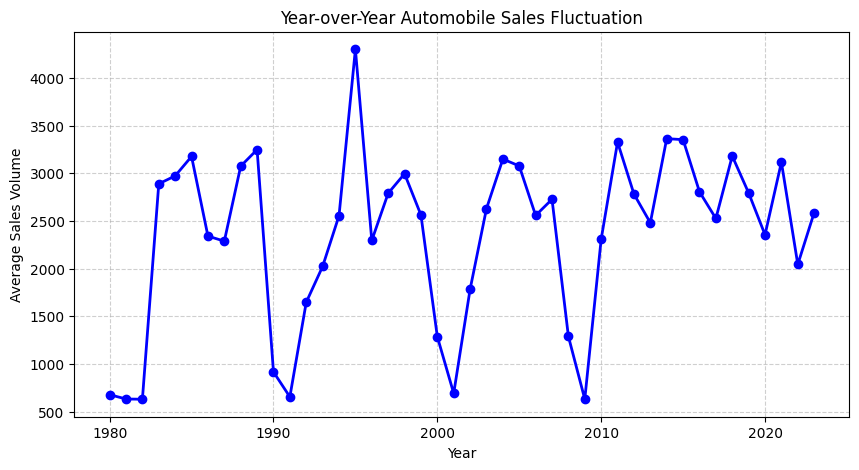

In [ ]:
has=has.sort_values('Year')
# 1. Group data by year and calculate mean sales volume
yearly_sales = has.groupby('Year')['Automobile_Sales'].mean()

# Plot using Pandas line chart
plt.figure(figsize=(10, 5))
yearly_sales.plot(kind='line', color='blue', marker='o', linewidth=2)

plt.title('Year-over-Year Automobile Sales Fluctuation')
plt.xlabel('Year')
plt.ylabel('Average Sales Volume')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

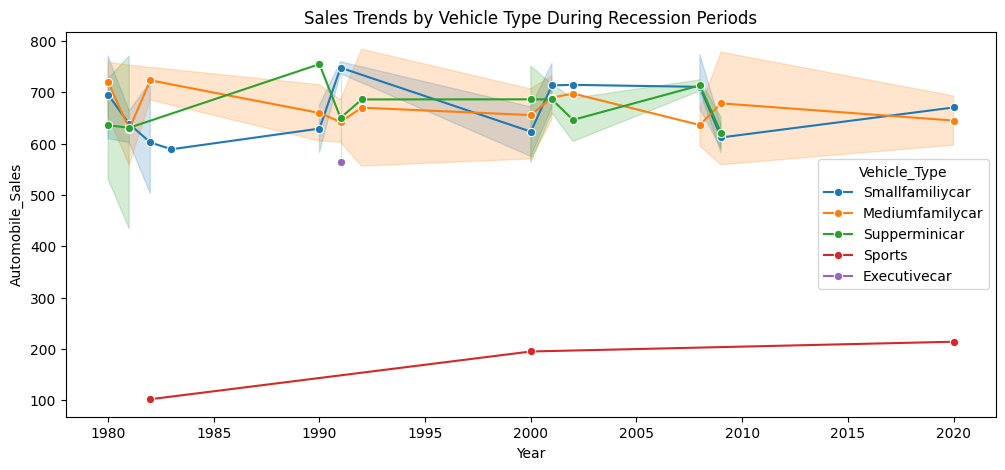

In [ ]:
# 2. Filter and plot trends by vehicle type during recessions
recession_df = has[has['Recession'] == 1]
plt.figure(figsize=(12, 5))
sns.lineplot(data=recession_df, x='Year', y='Automobile_Sales', hue='Vehicle_Type', marker='o')
plt.title('Sales Trends by Vehicle Type During Recession Periods')
plt.show()

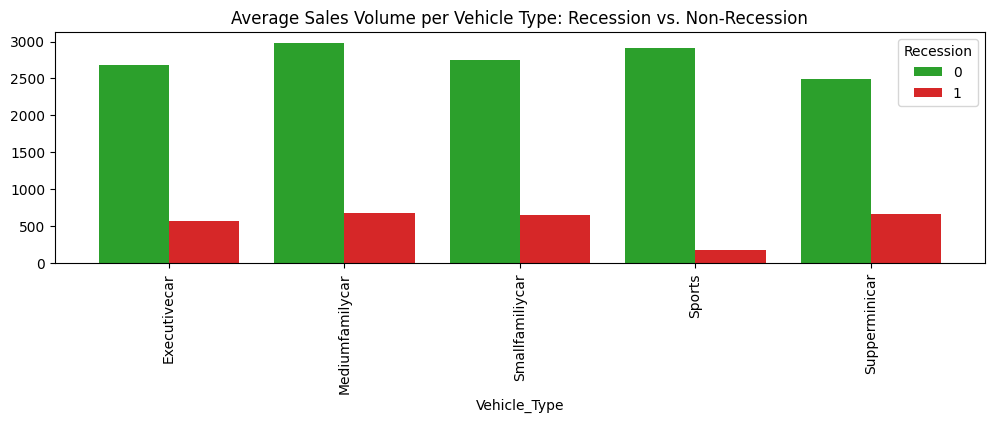

In [ ]:
# 3.
comparison_data = has.groupby(['Vehicle_Type', 'Recession'])['Automobile_Sales'].mean().unstack()
comparison_data.plot(kind='bar', figsize=(12, 3), width=0.8, color=['#2ca02c', '#d62728'])
plt.title('Average Sales Volume per Vehicle Type: Recession vs. Non-Recession')
plt.show()

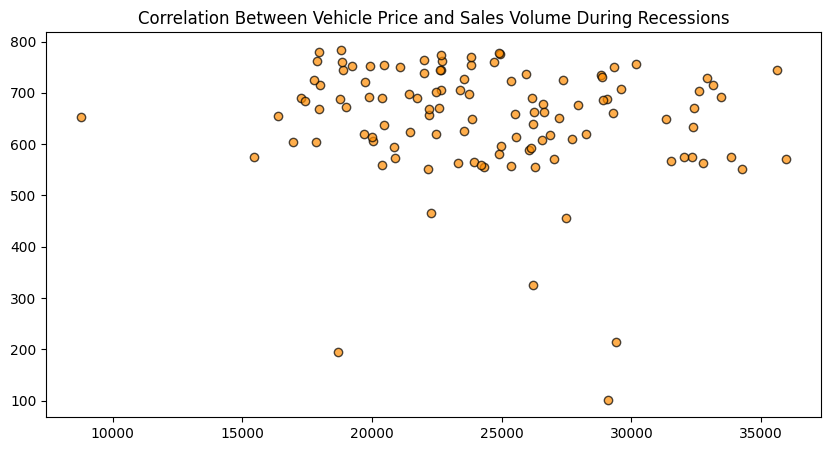

In [ ]:
# 4.
plt.figure(figsize=(10, 5))
plt.scatter(recession_df['Price'], recession_df['Automobile_Sales'], color='darkorange', alpha=0.7, edgecolors='black')
plt.title('Correlation Between Vehicle Price and Sales Volume During Recessions')
plt.show()

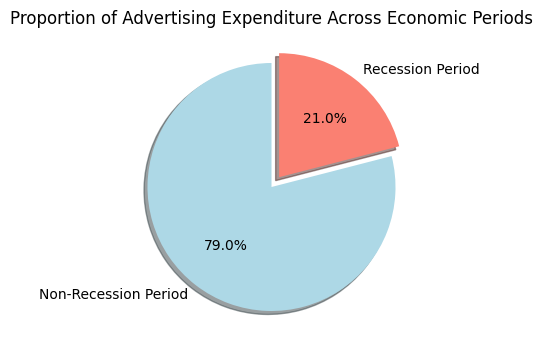

In [ ]:
# 5.
ad_spend = has.groupby('Recession')['Advertising_Expenditure'].sum()
plt.figure(figsize=(4, 8))
plt.pie(ad_spend, labels=['Non-Recession Period', 'Recession Period'], autopct='%1.1f%%', startangle=90, colors=['lightblue', 'salmon'], explode=(0, 0.1), shadow=True)
plt.title('Proportion of Advertising Expenditure Across Economic Periods')
plt.show()

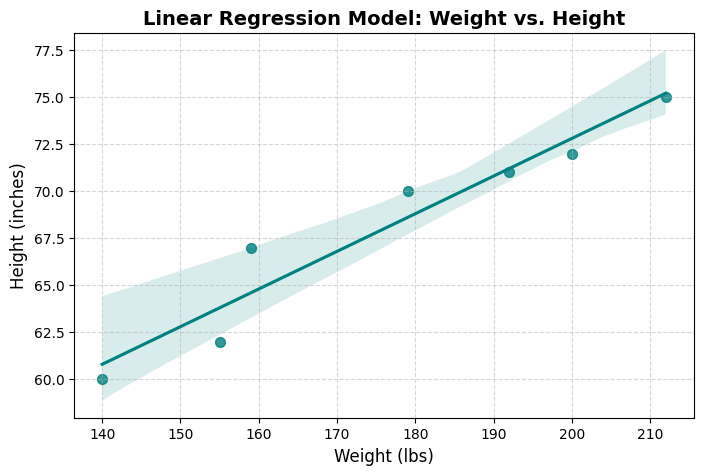

In [ ]:
# Create the DataFrame
wh = {
    'weight_lbs': [140, 155, 159, 179, 192, 200, 212],
    'height_inches': [60, 62, 67, 70, 71, 72, 75]
}
whdf = pd.DataFrame(wh)

# Plot the linear regression model using Seaborn
plt.figure(figsize=(8, 5))
sns.regplot(data=whdf, x='weight_lbs', y='height_inches', color='teal', marker='o', scatter_kws={'s': 50})

# Add labels and layout styling
plt.title('Linear Regression Model: Weight vs. Height', fontsize=14, fontweight='bold')
plt.xlabel('Weight (lbs)', fontsize=12)
plt.ylabel('Height (inches)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

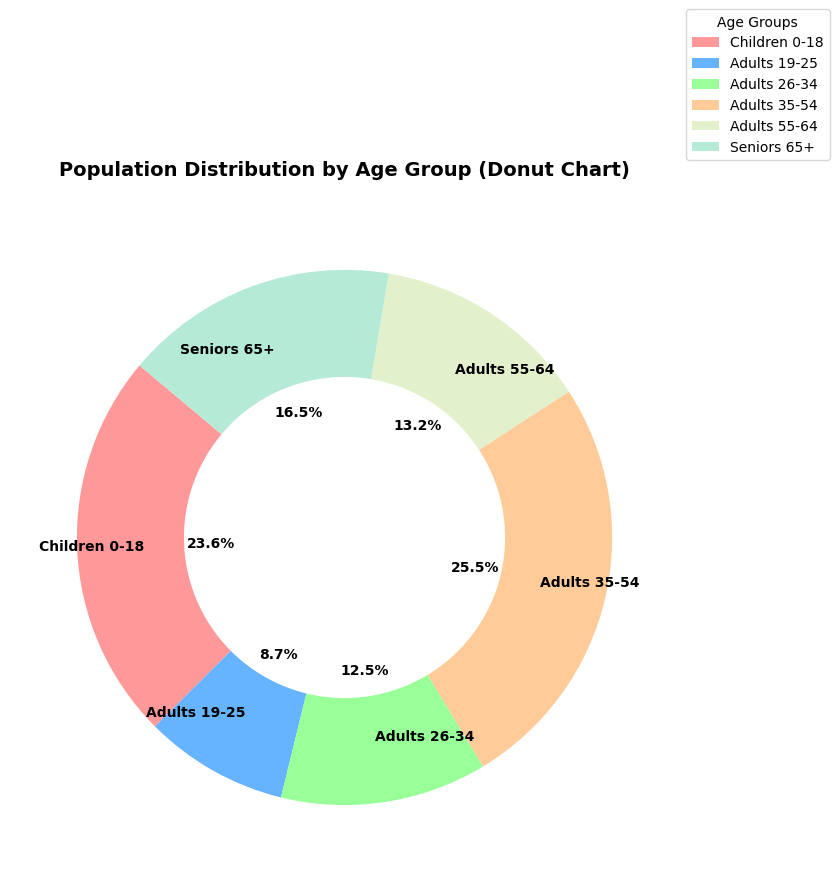

In [ ]:
# Prepare data from your table (Requirement 1)
labels = [
    'Children 0-18',
    'Adults 19-25',
    'Adults 26-34',
    'Adults 35-54',
    'Adults 55-64',
    'Seniors 65+'
]
sizes = [75307800, 27799100, 39817700, 81478600, 42061700, 52784400]

# Define a clean custom color palette (Requirement 3)
custom_colors = ['#FF9999', '#66B3FF', '#99FF99', '#FFCC99', '#E2F0CB', '#B5EAD7']

plt.figure(figsize=(9, 9))

# Create the pie chart mapping all customized requirements
# - autopct: Shows percentages inside the chart (Requirement 2)
# - colors: Applies custom color profile (Requirement 3)
# - labeldistance: Lowering distance value (0.75) forces category text INSIDE the slices (Requirement 4)
# - textprops: Dictionary handles font weight styling directly in bold (Requirement 4)
wedges, texts, autotexts = plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    colors=custom_colors,
    startangle=140,
    labeldistance=0.75,
    pctdistance=0.50,
    textprops={'weight': 'bold', 'fontsize': 10}
)

# Enforce bold properties onto percentages text layer too (Requirement 4)
for autotext in autotexts:
    autotext.set_weight('bold')
    autotext.set_fontsize(10)

# Convert the standard pie chart into a Donut Chart (Requirement 5)
# Draw a clean white circle in the center with a radius of 0.60 to create the hole
centre_circle = plt.Circle((0,0), 0.60, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)
# plt.gcf() tells Matplotlib, "Find the active window canvas I am currently working on and grab a reference to it."
# plt.gca() tells Matplotlib, "Find the active plot frame inside the window."

# Add an external legend (Requirement 3)
plt.legend(wedges, labels, title="Age Groups", loc="upper left", bbox_to_anchor=(1, 1, 0.3, 0.3))
# bbox_to_anchor(x, y, width, height) -- By default, Matplotlib tries to find the best empty spot inside your chart to
# place the legend. bbox_to_anchor overrides this behavior completely, letting you anchor it anywhere using coordinates.

# Graph metadata configurations
plt.title('Population Distribution by Age Group (Donut Chart)', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

# Render the output visualization
plt.show()

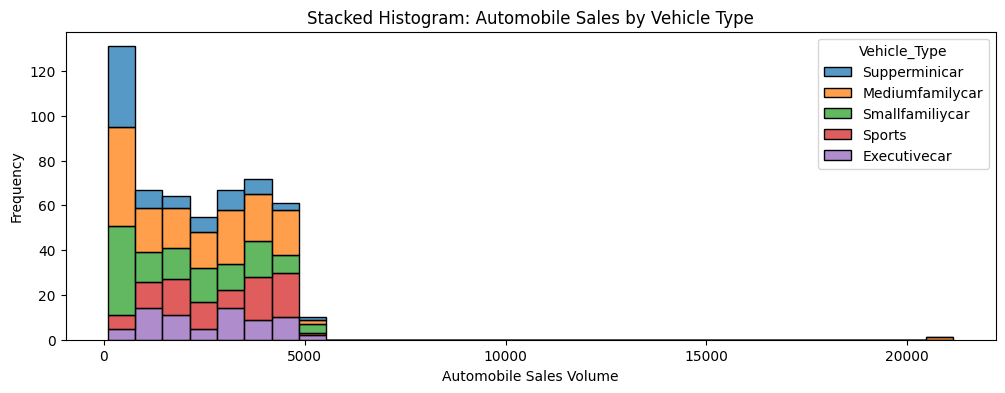

In [3]:
has0=pd.read_csv('/content/historical_automobile_sales.csv')
plt.figure(figsize=(12, 4))
sns.histplot(data=has0, x="Automobile_Sales", hue="Vehicle_Type", multiple="stack", palette="tab10")
plt.title("Stacked Histogram: Automobile Sales by Vehicle Type")
plt.xlabel("Automobile Sales Volume")
plt.ylabel("Frequency")
plt.show()

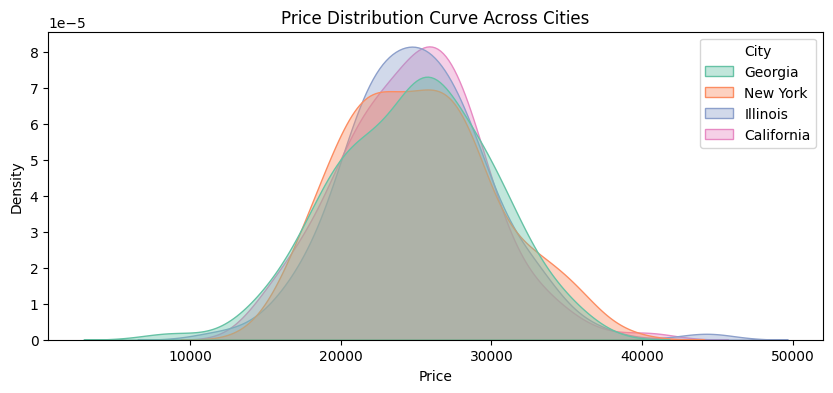

In [4]:
plt.figure(figsize=(10, 4))
sns.kdeplot(data=has0, x="Price", hue="City", fill=True, common_norm=False, palette="Set2", alpha=0.4)
plt.title("Price Distribution Curve Across Cities")
plt.xlabel("Price")
plt.ylabel("Density")
plt.show()

<Figure size 1100x400 with 0 Axes>

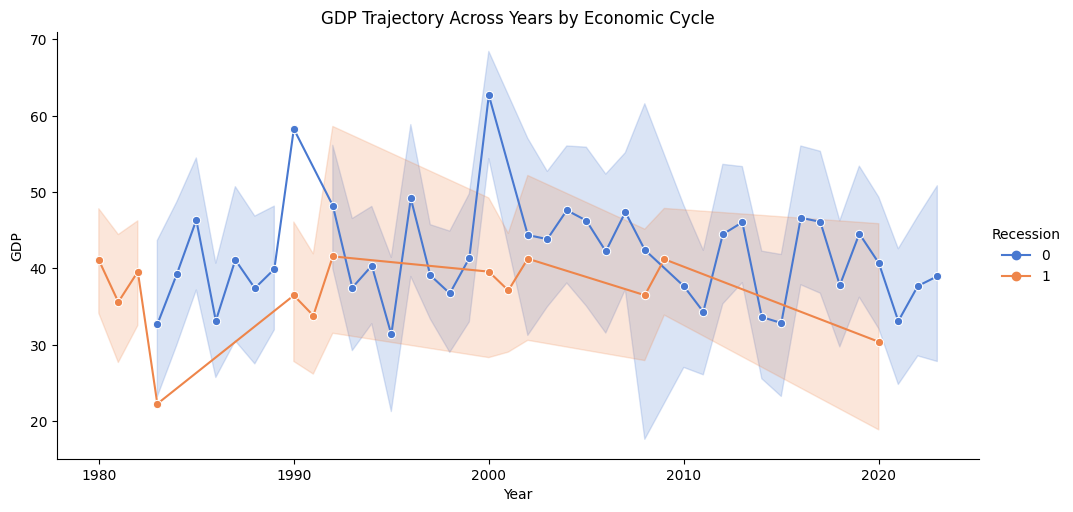

In [6]:
plt.figure(figsize=(11, 4))
sns.relplot(data=has0, x="Year", y="GDP", hue="Recession", kind="line", marker="o", aspect=2, palette="muted")
plt.title("GDP Trajectory Across Years by Economic Cycle")
plt.show()

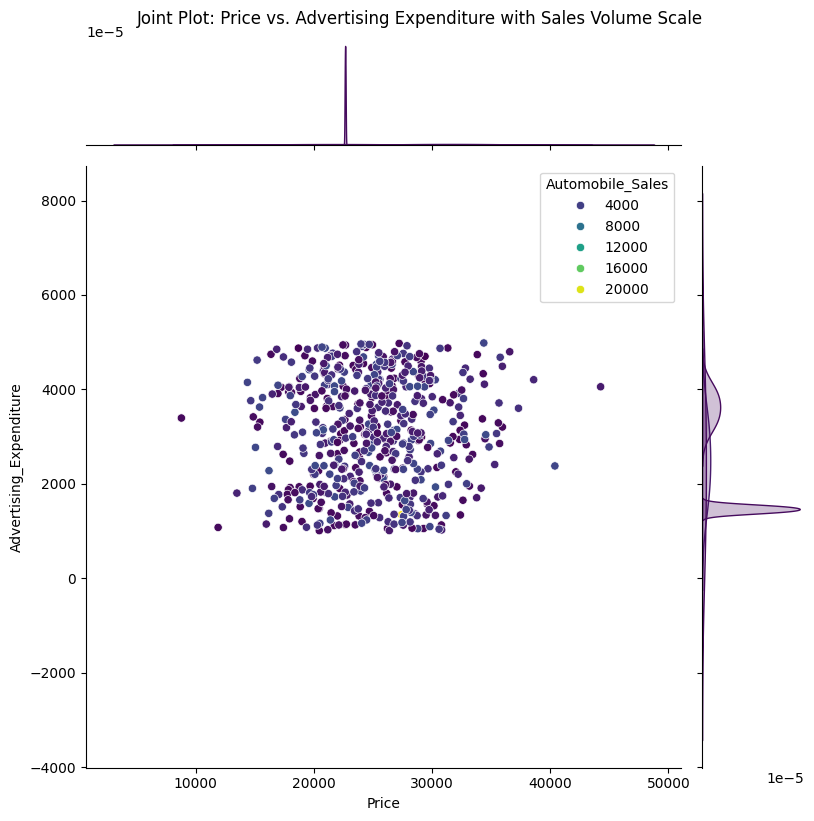

In [7]:
# Mapping scatter positions with sizes scaling based on Sales metrics
g = sns.jointplot(data=has0, x="Price", y="Advertising_Expenditure", hue="Automobile_Sales", palette="viridis", height=8)
g.fig.suptitle("Joint Plot: Price vs. Advertising Expenditure with Sales Volume Scale", y=1.02)
plt.show()

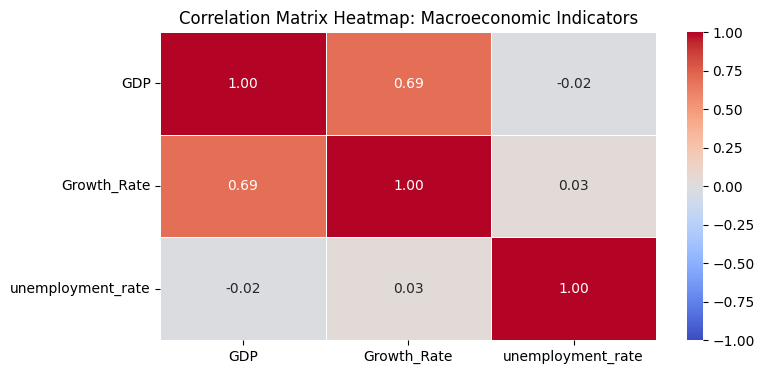

In [10]:
plt.figure(figsize=(8, 4))
macro_corr = has0[["GDP", "Growth_Rate", "unemployment_rate"]].corr()
sns.heatmap(macro_corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Matrix Heatmap: Macroeconomic Indicators")
plt.show()

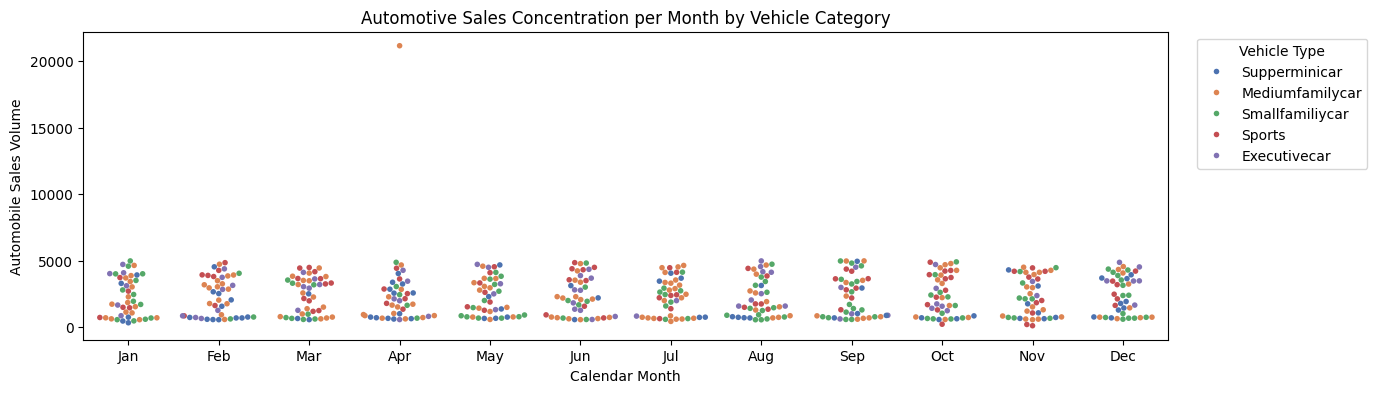

In [12]:
# Order months chronologically for clean reading flow
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
plt.figure(figsize=(14, 4))
sns.swarmplot(data=has0, x="Month", y="Automobile_Sales", hue="Vehicle_Type", order=month_order, size=4, palette="deep")
plt.title("Automotive Sales Concentration per Month by Vehicle Category")
plt.xlabel("Calendar Month")
plt.ylabel("Automobile Sales Volume")
plt.legend(title="Vehicle Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

/tmp/ipykernel_437/3027967941.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=has0, x="Year", y="Consumer_Confidence", palette="pastel", inner="quartile")


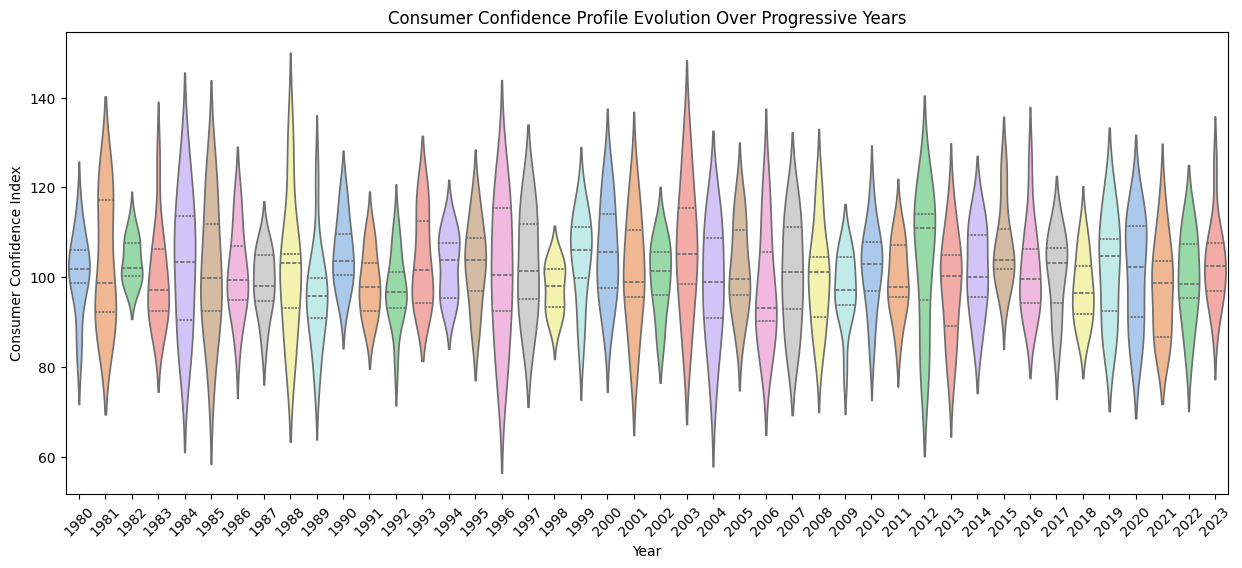

In [20]:
plt.figure(figsize=(15, 6))
sns.violinplot(data=has0, x="Year", y="Consumer_Confidence", palette="pastel", inner="quartile")
plt.title("Consumer Confidence Profile Evolution Over Progressive Years")
plt.xlabel("Year")
plt.ylabel("Consumer Confidence Index")
plt.xticks(rotation=45)
plt.show()

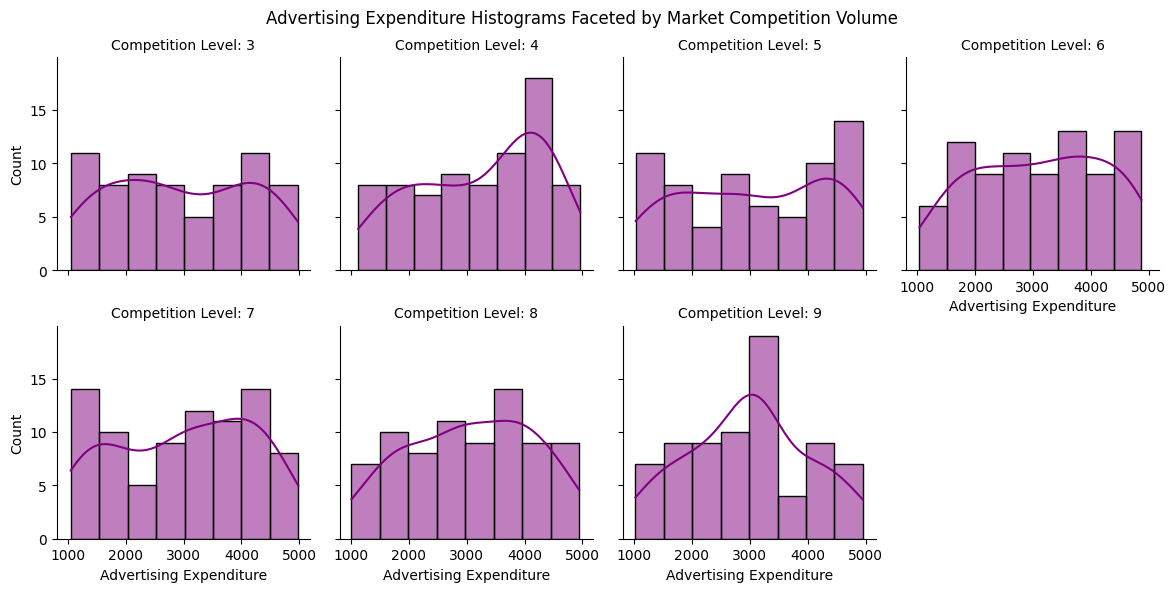

In [22]:
g = sns.FacetGrid(has0, col="Competition", col_wrap=4, height=3, sharey=True)
g.map(sns.histplot, "Advertising_Expenditure", color="purple", kde=True)
g.set_titles("Competition Level: {col_name}")
g.set_axis_labels("Advertising Expenditure", "Count")
plt.subplots_adjust(top=0.9)
g.fig.suptitle("Advertising Expenditure Histograms Faceted by Market Competition Volume")
plt.show()